<a href="https://colab.research.google.com/github/prashikrangari/DL-ML/blob/main/Crop_Recommendation_Using_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install pandas

In [ ]:
!pip install numpy

In [ ]:
!pip install scikit-learn

In [ ]:
!pip install matplotlib

In [ ]:
!pip install seaborn

In [ ]:
!pip install joblib

In [ ]:
import sys
# Auto-install streamlit if it is not installed
try:
    import streamlit as st
except ImportError:
    !pip install -q streamlit
    import streamlit as st

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

import joblib

print("All libraries imported successfully!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 41.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 78.7 MB/s eta 0:00:00
All libraries imported successfully!


In [ ]:
df = pd.read_csv("/content/Crop_recommendation.csv")

print(df.head())

    N   P   K  temperature   humidity        ph    rainfall label
0  90  42  43    20.879744  82.002744  6.502985  202.935536  rice
1  85  58  41    21.770462  80.319644  7.038096  226.655537  rice
2  60  55  44    23.004459  82.320763  7.840207  263.964248  rice
3  74  35  40    26.491096  80.158363  6.980401  242.864034  rice
4  78  42  42    20.130175  81.604873  7.628473  262.717340  rice


In [ ]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns)

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (2200, 8)

Column Names:
Index(['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label'], dtype='object')

Missing Values:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64


To check the dataset

In [ ]:
print("Total Rows and Columns:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nCrop Names:")
print(df["label"].unique())

Total Rows and Columns: (2200, 8)

First 5 Rows:


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice



Crop Names:
['rice' 'maize' 'chickpea' 'kidneybeans' 'pigeonpeas' 'mothbeans'
 'mungbean' 'blackgram' 'lentil' 'pomegranate' 'banana' 'mango' 'grapes'
 'watermelon' 'muskmelon' 'apple' 'orange' 'papaya' 'coconut' 'cotton'
 'jute' 'coffee']


Separate  a input and output


In [ ]:
X = df[["N", "P", "K", "temperature",
        "humidity", "ph", "rainfall"]]

y = df["label"]

print("Input features:", X.shape)
print("Output labels:", y.shape)

Input features: (2200, 7)
Output labels: (2200,)


Training and Testing data


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1760, 7)
Testing data: (440, 7)


Train Random Forest Data

In [ ]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("SmartSeed AI model trained successfully!")

SmartSeed AI model trained successfully!


TO check the accuracy

In [ ]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 99.55 %


To compare a ML algorithms

In [ ]:
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "SVM": make_pipeline(
        StandardScaler(),
        SVC()
    )
}

results = []

for name, clf in models.items():
    clf.fit(X_train, y_train)
    predictions = clf.predict(X_test)

    score = accuracy_score(y_test, predictions) * 100

    results.append({
        "Algorithm": name,
        "Accuracy (%)": round(score, 2)
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="Accuracy (%)",
    ascending=False
)

display(results_df)

,Algorithm,Accuracy (%)
2,Random Forest,99.55
4,SVM,98.41
1,Decision Tree,97.95
3,KNN,97.95
0,Logistic Regression,97.27


Accuracy Graph Of eaxh Algorithm

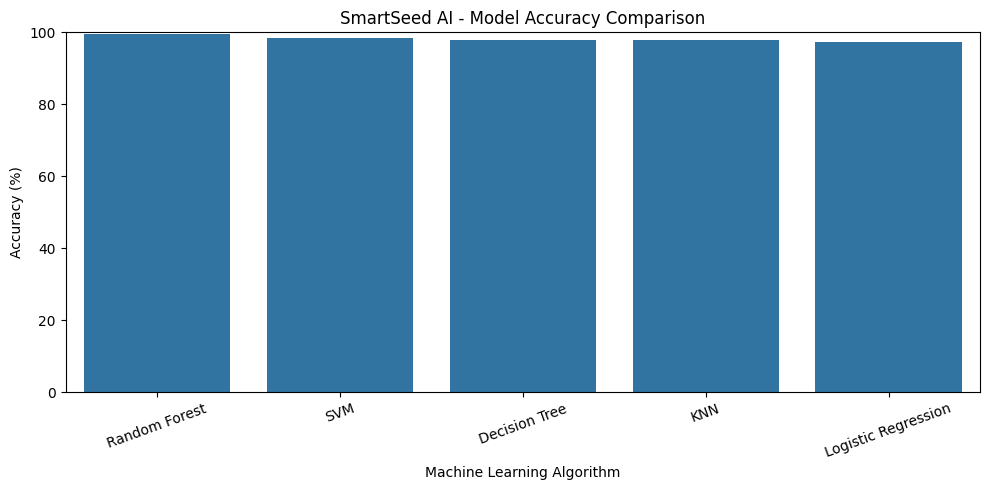

In [ ]:
# @title
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Algorithm",
    y="Accuracy (%)"
)

plt.title("SmartSeed AI - Model Accuracy Comparison")
plt.xlabel("Machine Learning Algorithm")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=20)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

To check a classification report

In [ ]:
y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        20
      papaya       1.00    

Create a Confusion Matrix

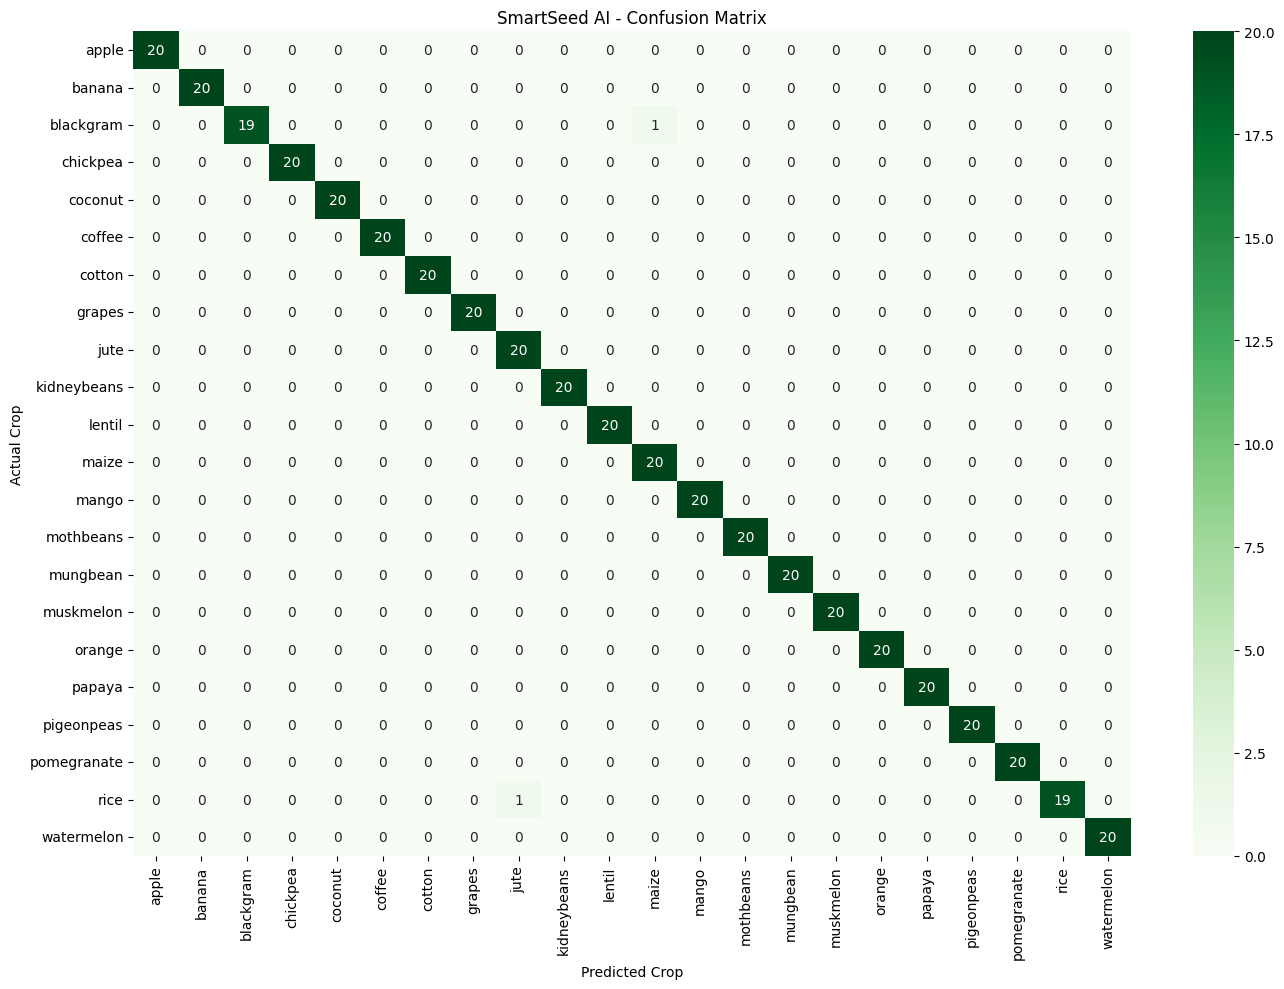

In [ ]:
# @title
plt.figure(figsize=(14, 10))

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.title("SmartSeed AI - Confusion Matrix")
plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

To predict a graph

In [ ]:
sample = pd.DataFrame([{
    "N": 90,
    "P": 42,
    "K": 43,
    "temperature": 20.8,
    "humidity": 82,
    "ph": 6.5,
    "rainfall": 202.9
}])

prediction = model.predict(sample)

print("🌱 SmartSeed AI Recommendation")
print("Recommended Crop:", prediction[0])

🌱 SmartSeed AI Recommendation
Recommended Crop: rice


To save a trained model

In [ ]:
joblib.dump(model, "smartseed_model.pkl")

print("Model saved successfully!")

Model saved successfully!


To select a  best model

In [ ]:
best_model_name = results_df.iloc[0]["Algorithm"]

print("Best Algorithm:", best_model_name)
print("Best Accuracy:", results_df.iloc[0]["Accuracy (%)"], "%")

Best Algorithm: Random Forest
Best Accuracy: 99.55 %


To  save Random forest model

In [ ]:
best_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

best_model.fit(X_train, y_train)

joblib.dump(best_model, "smartseed_model.pkl")

print("SmartSeed AI model saved successfully!")

SmartSeed AI model saved successfully!


To test a crop prediction

In [ ]:
sample = pd.DataFrame([{
    "N": 90,
    "P": 42,
    "K": 43,
    "temperature": 20.8,
    "humidity": 82,
    "ph": 6.5,
    "rainfall": 202.9
}])

crop = best_model.predict(sample)[0]

print("🌱 SmartSeed AI")
print("Recommended Crop:", crop)

🌱 SmartSeed AI
Recommended Crop: rice


Download a model

In [ ]:
from google.colab import files

files.download("smartseed_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

To create a dashboard

In [ ]:
!pip install streamlit pyngrok

In [ ]:
# @title

%%writefile /content/app.py

import streamlit as st
import pandas as pd
import joblib

st.set_page_config(
    page_title="SmartSeed AI",
    page_icon="🌱",
    layout="wide"
)

@st.cache_resource
def load_model():
    return joblib.load("/content/smartseed_model.pkl")

model = load_model()
if "history" not in st.session_state:
    st.session_state.history = []

st.markdown("""
<style>
.stApp {
    background-color: #f4f9f2;
}
.main-title {
    color: #176b37;
    font-size: 42px;
    font-weight: 800;
}
.subtitle {
    color: #55745d;
    font-size: 17px;
}
div.stButton > button {
    background-color: #198754;
    color: white;
    border-radius: 10px;
    height: 48px;
    width: 100%;
    font-size: 18px;
    font-weight: bold;
}
div.stButton > button:hover {
    background-color: #126b40;
    color: white;
    border: 1px solid #126b40;
}
</style>
""", unsafe_allow_html=True)

st.markdown(
    '<div class="main-title">🌱 SmartSeed AI</div>',
    unsafe_allow_html=True
)
st.markdown(
    '<div class="subtitle">AI-Powered Crop Recommendation System</div>',
    unsafe_allow_html=True
)

st.divider()

st.info(
    "Enter soil nutrient and weather values to find "
    "a crop predicted by the machine learning model."
)

left, right = st.columns(2)

with left:
    st.subheader("🧪 Soil Information")

    N = st.number_input("Nitrogen (N)", 0.0, 200.0, 90.0)
    P = st.number_input("Phosphorus (P)", 0.0, 200.0, 42.0)
    K = st.number_input("Potassium (K)", 0.0, 250.0, 43.0)
    ph = st.number_input("Soil pH", 0.0, 14.0, 6.5)

with right:
    st.subheader("🌦️ Weather Information")

    temperature = st.number_input(
        "Temperature (°C)", -10.0, 60.0, 20.8
    )
    humidity = st.number_input(
        "Humidity (%)", 0.0, 100.0, 82.0
    )
    rainfall = st.number_input(
        "Rainfall (mm)", 0.0, 5000.0, 202.9
    )

st.divider()

if st.button("🌾 Recommend Best Crop"):
    input_data = pd.DataFrame([{
        "N": N,
        "P": P,
        "K": K,
        "temperature": temperature,
        "humidity": humidity,
        "ph": ph,
        "rainfall": rainfall
    }])

    prediction = model.predict(input_data)[0]

    st.session_state.history.append({
        "Nitrogen": N,
        "Phosphorus": P,
        "Potassium": K,
        "Temperature": temperature,
        "Humidity": humidity,
        "pH": ph,
        "Rainfall": rainfall,
        "Recommended Crop": prediction.title()
    })
    st.success("Crop prediction completed!")

    st.markdown("### 🌿 Recommended Crop")
    st.markdown(f"# {prediction.title()}")

    st.caption(
        "This prediction is based on the training dataset. "
        "Actual crop suitability depends on local soil, climate, "
        "season and farming conditions."
    )

st.divider()
st.header("📋 Prediction History")

if st.session_state.history:
    history_df = pd.DataFrame(st.session_state.history)

    st.dataframe(history_df, use_container_width=True)

    csv_data = history_df.to_csv(index=False).encode("utf-8")

    st.download_button(
        label="📥 Download Prediction Report (CSV)",
        data=csv_data,
        file_name="SmartSeed_Prediction_History.csv",
        mime="text/csv"
    )
else:
    st.info("No predictions yet. Predict a crop first!")


Writing /content/app.py


In [ ]:
# @title
%%writefile -a /content/app.py

# --- Model Analytics ---
st.divider()
st.header("📊 Model Analytics")

# Crop Distribution
st.subheader("🌾 Crop Distribution")

df = pd.read_csv("/content/Crop_recommendation.csv")

if "label" in df.columns:
    crop_counts = df["label"].value_counts()
    st.bar_chart(crop_counts)

# Model Accuracy Comparison
st.subheader("📈 Model Accuracy Comparison")

results_data = pd.DataFrame([
    {"Algorithm": "Random Forest", "Accuracy (%)": 99.55},
    {"Algorithm": "SVM", "Accuracy (%)": 98.41},
    {"Algorithm": "Decision Tree", "Accuracy (%)": 97.95},
    {"Algorithm": "KNN", "Accuracy (%)": 97.95},
    {"Algorithm": "Logistic Regression", "Accuracy (%)": 97.27}
])

st.bar_chart(
    results_data.set_index("Algorithm")["Accuracy (%)"]
)

st.dataframe(results_data, use_container_width=True)

Appending to /content/app.py


In [ ]:
!grep -n "Model Analytics" /content/app.py

145:# --- Model Analytics ---
147:st.header("📊 Model Analytics")
198:# --- Model Analytics Section ---
203:st.header("📊 Model Analytics")


In [ ]:
!sed -i '145,173d' /content/app.py

To add a History and CSV download section

In [ ]:
# @title
%%writefile -a /content/app.py

# --- Prediction History & CSV Download ---
st.divider()
st.header("📋 Prediction History")

if st.session_state.history:
    history_df = pd.DataFrame(st.session_state.history)

    st.dataframe(history_df, use_container_width=True)

    csv_data = history_df.to_csv(index=False).encode("utf-8")

    st.download_button(
        label="📥 Download Prediction Report (CSV)",
        data=csv_data,
        file_name="SmartSeed_Prediction_History.csv",
        mime="text/csv"
    )
else:
    st.info("No predictions yet. Predict a crop first!")

Appending to /content/app.py


In [ ]:
!streamlit run app.py &>/content/streamlit.log &

In [ ]:
!pip -q install streamlit
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared

In [ ]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [ ]:
!streamlit run /content/app.py --server.port 8502 --server.address 0.0.0.0 > /content/streamlit2.log 2>&1 &

In [ ]:
!cat /content/streamlit2.log

Crop distribution and dataset analytics

Total Samples: 2200
Total Crop Types: 22
Missing Values: 0


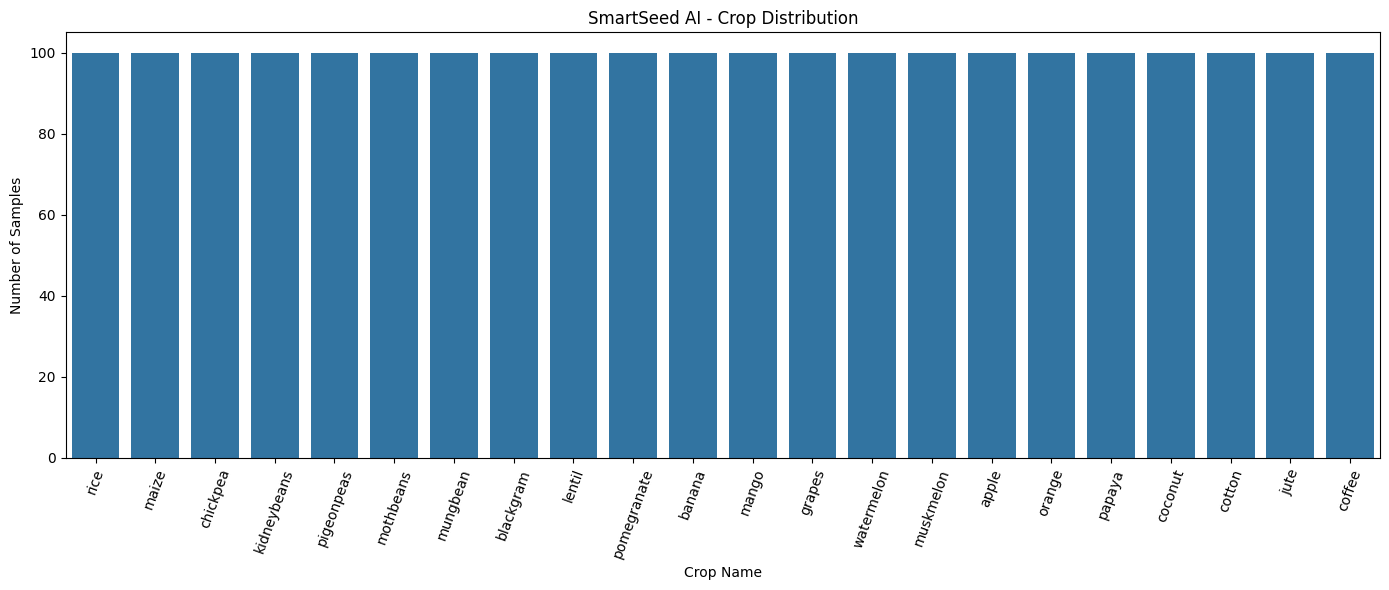

In [ ]:
# @title
# Dataset overview
print("Total Samples:", len(df))
print("Total Crop Types:", df["label"].nunique())
print("Missing Values:", df.isnull().sum().sum())

# Crop distribution graph
plt.figure(figsize=(14, 6))

sns.countplot(
    data=df,
    x="label",
    order=df["label"].value_counts().index
)

plt.title("SmartSeed AI - Crop Distribution")
plt.xlabel("Crop Name")
plt.ylabel("Number of Samples")
plt.xticks(rotation=70)
plt.tight_layout()
plt.show()

Model accuracy comparison graph

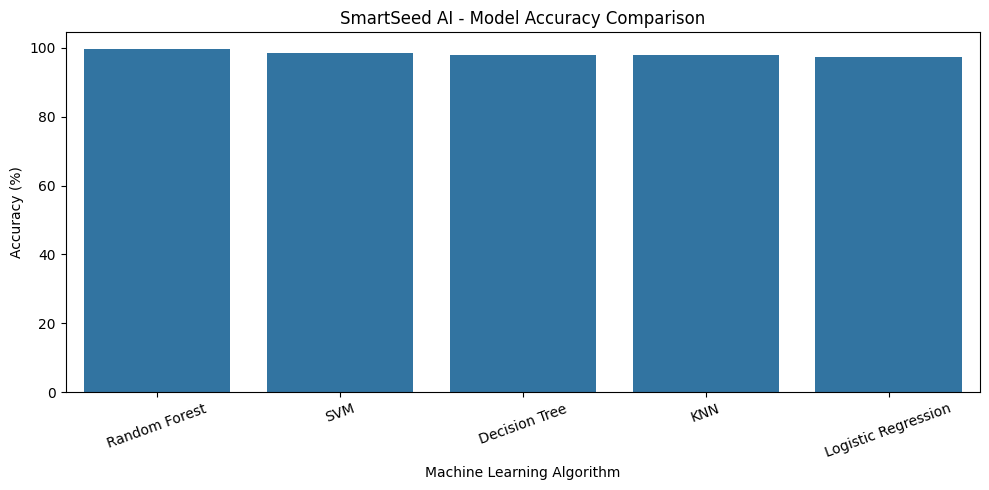

In [ ]:
# @title
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Algorithm",
    y="Accuracy (%)"
)

plt.title("SmartSeed AI - Model Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.xlabel("Machine Learning Algorithm")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig("/content/model_accuracy.png", dpi=300)
plt.show()

To show the graphs in dashboard

In [ ]:
# @title
%%writefile -a /content/app.py

# --- Model Analytics Section ---
import streamlit as st
import pandas as pd

st.divider()
st.header("📊 Model Analytics")

st.subheader("Crop Distribution")
df = pd.read_csv("/content/Crop_recommendation.csv")
if "label" in df.columns:
    crop_counts = df["label"].value_counts()
    st.bar_chart(crop_counts)

st.subheader("Model Accuracy Comparison")
# Re-create results_df to ensure it is available within the Streamlit runtime
results_data = pd.DataFrame([
    {"Algorithm": "Random Forest", "Accuracy (%)": 99.55},
    {"Algorithm": "SVM", "Accuracy (%)": 98.41},
    {"Algorithm": "Decision Tree", "Accuracy (%)": 97.95},
    {"Algorithm": "KNN", "Accuracy (%)": 97.95},
    {"Algorithm": "Logistic Regression", "Accuracy (%)": 97.27}
])
st.dataframe(results_data, use_container_width=True)

Appending to /content/app.py


To add prediction history

In [ ]:
!streamlit run /content/app.py --server.port 8503 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [ ]:
!nohup streamlit run /content/app.py --server.port 8503 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [ ]:
!sed -i 's/^# --- Prediction History & CSV Download ---/if "history" not in st.session_state:\n    st.session_state.history = []\n\n# --- Prediction History \& CSV Download ---/' /content/app.py

In [ ]:
!ps aux | grep '[s]treamlit'
!ls -l /content/app.py /content/smartseed_model.pkl /content/Crop_recommendation.csv
!tail -30 /content/streamlit.log

-rw-r--r-- 1 root root    4683 Oct 18 01:07 /content/app.py
-rw-r--r-- 1 root root  150034 Oct 18 01:00 /content/Crop_recommendation.csv
-rw-r--r-- 1 root root 3576361 Oct 18 01:04 /content/smartseed_model.pkl


2026-10-18 01:05:47.241 Uvicorn server started on 0.0.0.0:8503

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8503
  Network URL: http://172.28.0.12:8503
  External URL: http://34.24.151.131:8  Stopping...
g...


In [ ]:
!curl -I http://127.0.0.1:8503

HTTP/1.1 200 OK
date: Sun, 18 Oct 2026 01:12:18 GMT
server: uvicorn
content-type: text/html; charset=utf-8
accept-ranges: bytes
content-length: 6467
last-modified: Sun, 18 Oct 2026 01:02:27 GMT
etag: "1f2eb74c5d370efb367836dfeec49ae9"
cache-control: no-cache



In [ ]:
!sed -i '126,167d' /content/app.py

In [ ]:
!grep -n "Prediction History\|download_button\|Model Analytics" /content/app.py

In [ ]:
# @title
path = "/content/app.py"

with open(path, "r", encoding="utf-8") as f:
    code = f.read()

button_line = 'if st.button("🌾 Recommend Best Crop"):'

if button_line not in code:
    print("Error: Prediction button was not found in app.py.")
else:
    # Initialize session history before the prediction button.
    if 'if "history" not in st.session_state:' not in code:
        code = code.replace(
            button_line,
            'if "history" not in st.session_state:\n'
            '    st.session_state.history = []\n\n'
            + button_line,
            1
        )

    # Remove any previous restored section to prevent duplicates.
    marker = "# --- RESTORED HISTORY AND ANALYTICS ---"
    if marker in code:
        code = code.split(marker)[0].rstrip() + "\n"

    extra = '''

# --- RESTORED HISTORY AND ANALYTICS ---

st.divider()
st.header("📋 Prediction History")

if st.session_state.history:
    history_df = pd.DataFrame(st.session_state.history)
    st.dataframe(history_df, use_container_width=True)

    csv_data = history_df.to_csv(index=False).encode("utf-8")

    st.download_button(
        label="📥 Download Prediction Report (CSV)",
        data=csv_data,
        file_name="SmartSeed_Prediction_History.csv",
        mime="text/csv",
        key="history_csv_download"
    )
else:
    st.info("No predictions yet. Predict a crop first!")

# Model Analytics
st.divider()
st.header("📊 Model Analytics")

df = pd.read_csv("/content/Crop_recommendation.csv")

st.subheader("🌾 Crop Distribution")
if "label" in df.columns:
    st.bar_chart(df["label"].value_counts())

st.subheader("📈 Model Accuracy Comparison")

results_data = pd.DataFrame([
    {"Algorithm": "Random Forest", "Accuracy (%)": 99.55},
    {"Algorithm": "SVM", "Accuracy (%)": 98.41},
    {"Algorithm": "Decision Tree", "Accuracy (%)": 97.95},
    {"Algorithm": "KNN", "Accuracy (%)": 97.95},
    {"Algorithm": "Logistic Regression", "Accuracy (%)": 97.27}
])

st.bar_chart(results_data.set_index("Algorithm"))
st.dataframe(results_data, use_container_width=True)
'''

    with open(path, "w", encoding="utf-8") as f:
        f.write(code.rstrip() + "\n" + extra)

    print("Prediction History and Model Analytics restored successfully.")

Prediction History and Model Analytics restored successfully.


In [ ]:
!pkill -f "streamlit run /content/app.py" || true

^C


In [ ]:
!nohup streamlit run /content/app.py --server.port 8503 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [ ]:
!curl -I http://127.0.0.1:8503

HTTP/1.1 200 OK
date: Sun, 18 Oct 2026 01:46:50 GMT
server: uvicorn
content-type: text/html; charset=utf-8
accept-ranges: bytes
content-length: 6467
last-modified: Sun, 18 Oct 2026 01:02:27 GMT
etag: "1f2eb74c5d370efb367836dfeec49ae9"
cache-control: no-cache



In [ ]:
!./cloudflared tunnel --url http://127.0.0.1:8503

2026-10-18T01:47:13Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-18T01:47:13Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-10-18T01:47:16Z INF +--------------------------------------------------------------------------------------------+
2026-10-18T01:47:16Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-10-18T01:47:16Z INF |  https://problems-quoted-jackets-webmaster.trycloudfla